# SpaceX Falcon 9 — Exploratory Data Analysis

## Objective
Analyze Falcon 9 launch data using Pandas, Matplotlib, and Seaborn
to explore relationships between launch characteristics and
the course-defined landing classification.

Dataset: Historical Falcon 9 launches (2010–2020)

In [1]:
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All EDA libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Seaborn version:", sns.__version__)

All EDA libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.4.6
Seaborn version: 0.13.2


## Step 2 — Loading the Processed Dataset

Load the cleaned historical SpaceX dataset containing launch
characteristics and the binary classification target.

In [2]:
# Step 2: Upload and load the processed dataset

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("spacex_launches_processed.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Saving spacex_launches_processed.csv to spacex_launches_processed.csv
Dataset loaded successfully!
Dataset shape: (90, 18)

First five records:


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,1
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,1
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,1
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,1



Column names:
['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude', 'Class']


## Step 3 — Statistical Summary and Missing Values

Examine the numerical characteristics of the SpaceX dataset
and identify missing values before performing visual analysis.

In [3]:
# Step 3: Explore dataset statistics and missing values

print("Statistical summary:")
display(df.describe())

print("\nMissing values by column:")
display(df.isnull().sum().to_frame(name="MissingValues"))

print("\nTarget class distribution:")
display(df["Class"].value_counts().sort_index())

Statistical summary:


,FlightNumber,PayloadMass,Flights,Block,ReusedCount,Longitude,Latitude,Class
count,90.000000,90.000000,90.000000,90.000000,90.000000,90.000000,90.000000,90.000000
mean,45.500000,6104.959412,1.788889,3.500000,1.655556,-86.366477,29.449963,0.877778
std,26.124701,4694.671720,1.213172,1.595288,1.710254,14.149518,2.141306,0.329377
min,1.000000,350.000000,1.000000,1.000000,0.000000,-120.610829,28.561857,0.000000
25%,23.250000,2510.750000,1.000000,2.000000,0.000000,-80.603956,28.561857,1.000000
50%,45.500000,4701.500000,1.000000,4.000000,1.000000,-80.577366,28.561857,1.000000
75%,67.750000,8912.750000,2.000000,5.000000,3.000000,-80.577366,28.608058,1.000000
max,90.000000,15600.000000,6.000000,5.000000,5.000000,-80.577366,34.632093,1.000000



Missing values by column:


,MissingValues
FlightNumber,0
Date,0
BoosterVersion,0
PayloadMass,0
Orbit,0
LaunchSite,0
Outcome,0
Flights,0
GridFins,0
Reused,0



Target class distribution:


,count
Class,
0,11
1,79


## Step 4 — Flight Number vs Payload Mass

Visualize the relationship between flight number and payload mass,
using the course-defined landing classification as the hue.

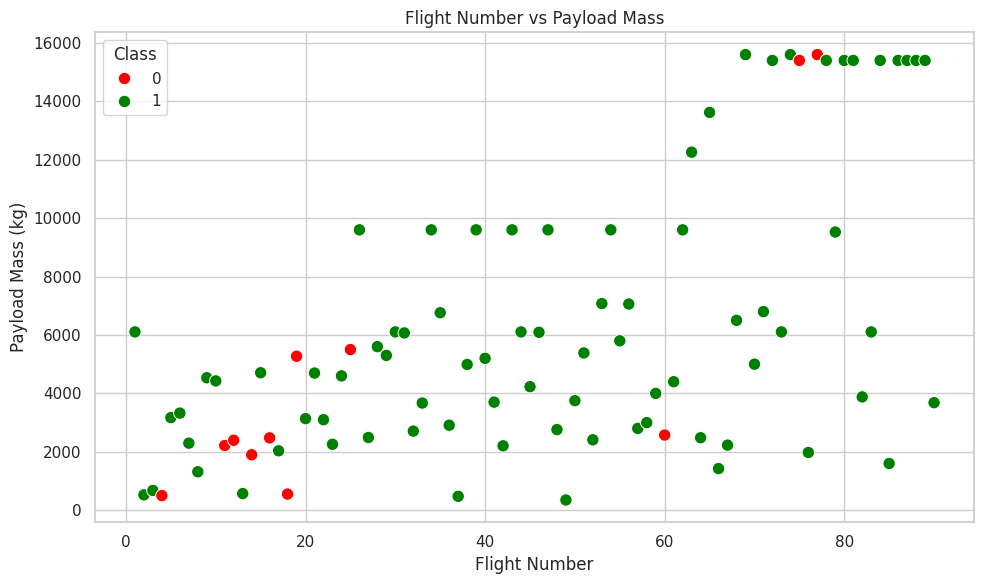

In [4]:
# Step 4: Flight Number vs Payload Mass

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="FlightNumber",
    y="PayloadMass",
    hue="Class",
    palette={0: "red", 1: "green"},
    s=80
)

plt.title("Flight Number vs Payload Mass")
plt.xlabel("Flight Number")
plt.ylabel("Payload Mass (kg)")
plt.legend(title="Class")
plt.tight_layout()

plt.show()

## Step 5 — Class 1 Percentage by Flight Group

Group consecutive flight numbers into intervals of 10 and
calculate the Class 1 percentage for each group.

,FlightGroup,count,mean,Class1Percentage
0,1,10,0.9,90.0
1,2,10,0.4,40.0
2,3,10,0.9,90.0
3,4,10,1.0,100.0
4,5,10,1.0,100.0
5,6,10,0.9,90.0
6,7,10,1.0,100.0
7,8,10,0.8,80.0
8,9,10,1.0,100.0


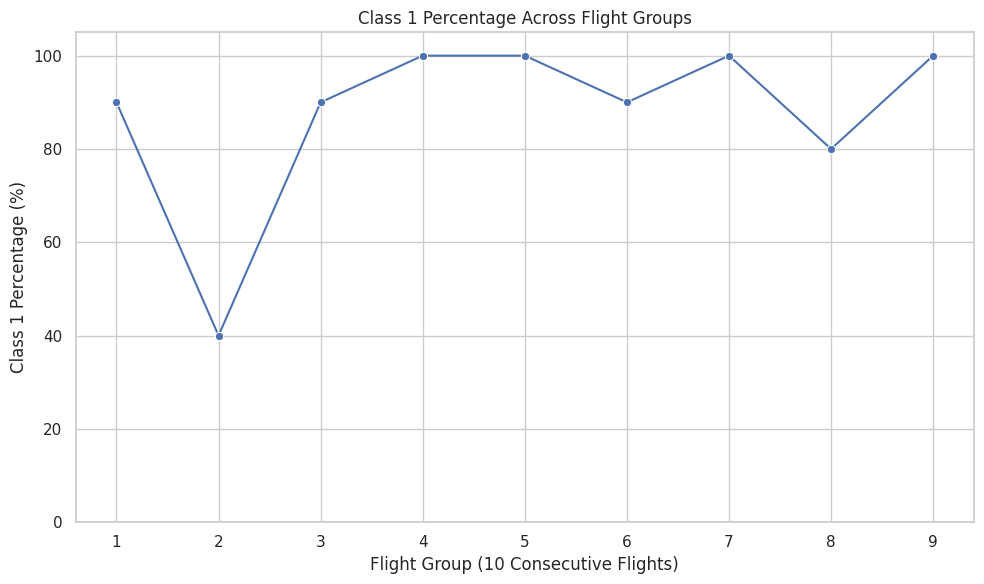

In [5]:
# Step 5: Class 1 percentage by flight group

df["FlightGroup"] = ((df["FlightNumber"] - 1) // 10) + 1

flight_trends = (
    df.groupby("FlightGroup")["Class"]
    .agg(["count", "mean"])
    .reset_index()
)

flight_trends["Class1Percentage"] = flight_trends["mean"] * 100

display(flight_trends)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=flight_trends,
    x="FlightGroup",
    y="Class1Percentage",
    marker="o"
)

plt.title("Class 1 Percentage Across Flight Groups")
plt.xlabel("Flight Group (10 Consecutive Flights)")
plt.ylabel("Class 1 Percentage (%)")
plt.ylim(0, 105)
plt.xticks(range(1, 10))
plt.tight_layout()

plt.show()

## Step 6 — Payload Mass vs Landing Classification

Analyze the relationship between payload mass and the
course-defined landing classification using payload categories.

Class 1 percentage by payload mass range:


,PayloadGroup,count,mean,Class1Percentage
0,0–3000,29,0.758621,75.862069
1,3000–6000,26,0.923077,92.307692
2,6000–9000,12,1.000000,100.000000
3,9000–12000,8,1.000000,100.000000
4,12000–16000,15,0.866667,86.666667


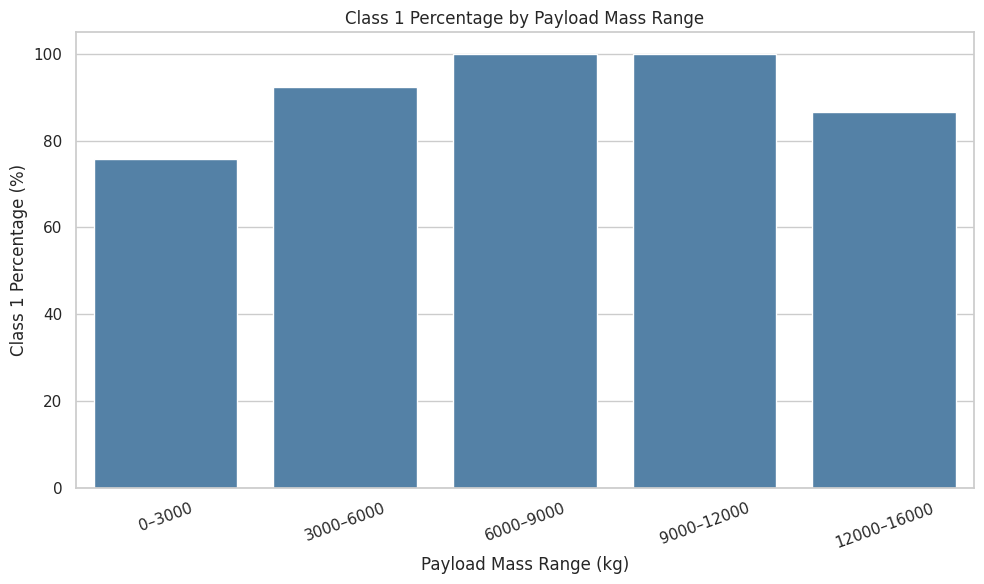

In [6]:
# Step 6: Analyze Class 1 percentage by payload mass range

payload_bins = [0, 3000, 6000, 9000, 12000, 16000]

payload_labels = [
    "0–3000",
    "3000–6000",
    "6000–9000",
    "9000–12000",
    "12000–16000"
]

df["PayloadGroup"] = pd.cut(
    df["PayloadMass"],
    bins=payload_bins,
    labels=payload_labels,
    include_lowest=True
)

payload_trends = (
    df.groupby("PayloadGroup", observed=True)["Class"]
    .agg(["count", "mean"])
    .reset_index()
)

payload_trends["Class1Percentage"] = (
    payload_trends["mean"] * 100
)

print("Class 1 percentage by payload mass range:")
display(payload_trends)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=payload_trends,
    x="PayloadGroup",
    y="Class1Percentage",
    color="steelblue"
)

plt.title("Class 1 Percentage by Payload Mass Range")
plt.xlabel("Payload Mass Range (kg)")
plt.ylabel("Class 1 Percentage (%)")
plt.ylim(0, 105)
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

## Step 7 — Payload Mass Distribution by Launch Site

Use a box plot to compare payload mass distributions across
the three historical SpaceX launch sites.

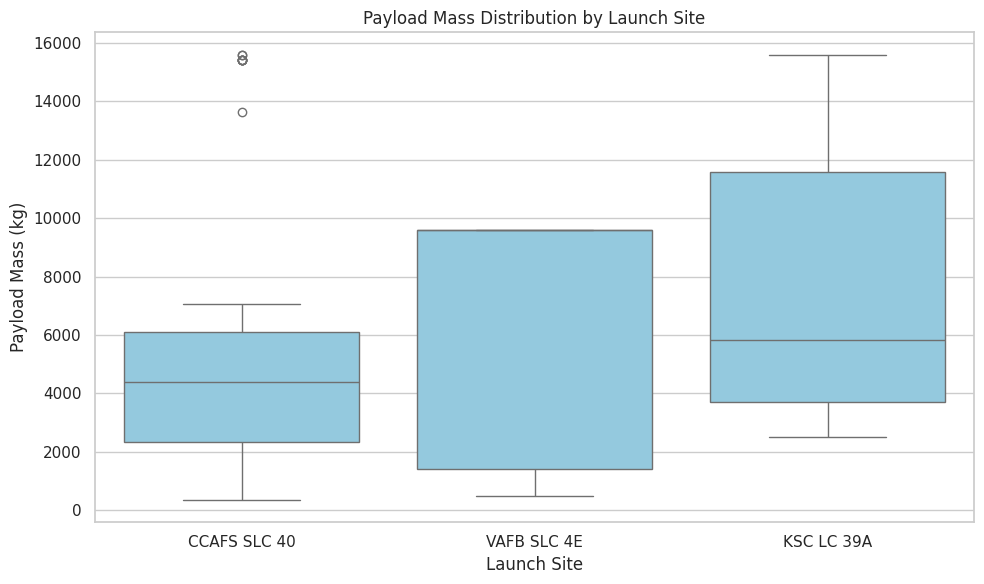

In [7]:
# Step 7: Compare payload mass distributions by launch site

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="LaunchSite",
    y="PayloadMass",
    color="skyblue"
)

plt.title("Payload Mass Distribution by Launch Site")
plt.xlabel("Launch Site")
plt.ylabel("Payload Mass (kg)")
plt.tight_layout()

plt.show()

## Step 8 — Launch Site vs Landing Classification

Calculate and visualize the percentage of Class 1 records
at each SpaceX launch site using Pandas and Seaborn.

Class 1 percentage by launch site:


,LaunchSite,count,sum,mean,Class1Percentage
1,KSC LC 39A,22,21,0.954545,95.454545
0,CCAFS SLC 40,55,47,0.854545,85.454545
2,VAFB SLC 4E,13,11,0.846154,84.615385


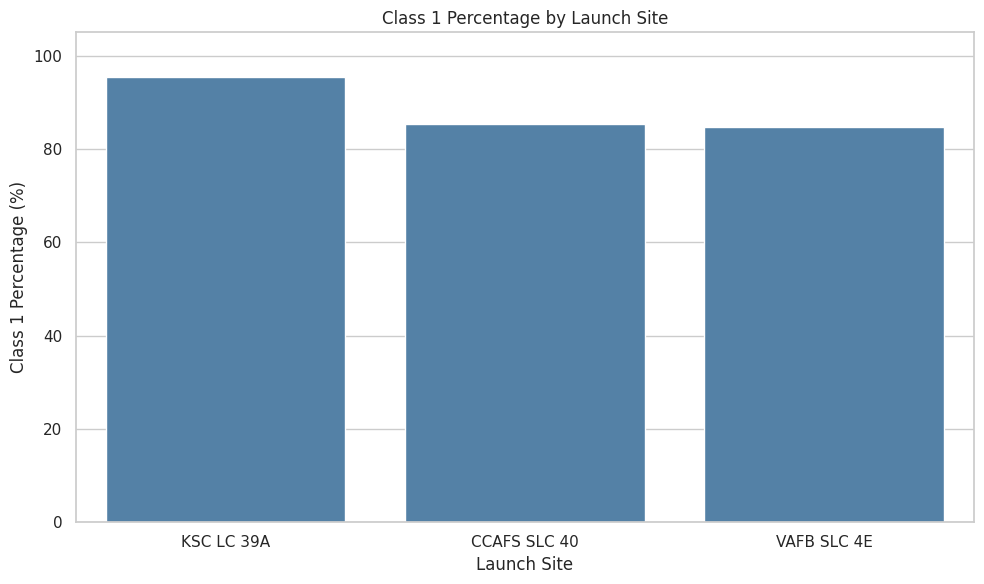

In [8]:
# Step 8: Analyze Class 1 percentage by launch site

site_results = (
    df.groupby("LaunchSite")["Class"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

site_results["Class1Percentage"] = (
    site_results["mean"] * 100
)

site_results = site_results.sort_values(
    "Class1Percentage",
    ascending=False
)

print("Class 1 percentage by launch site:")
display(site_results)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=site_results,
    x="LaunchSite",
    y="Class1Percentage",
    color="steelblue"
)

plt.title("Class 1 Percentage by Launch Site")
plt.xlabel("Launch Site")
plt.ylabel("Class 1 Percentage (%)")
plt.ylim(0, 105)
plt.tight_layout()

plt.show()

## Step 9 — Orbit vs Landing Classification

Analyze the number of launches and Class 1 percentage for each
orbital mission category using Pandas and Seaborn.

Class 1 percentage by orbit:


,Orbit,count,sum,mean,Class1Percentage
2,GTO,27,25,0.925926,92.592593
4,ISS,21,16,0.761905,76.190476
10,VLEO,14,12,0.857143,85.714286
7,PO,9,7,0.777778,77.777778
5,LEO,7,7,1.000000,100.000000
9,SSO,5,5,1.000000,100.000000
6,MEO,3,3,1.000000,100.000000
1,GEO,1,1,1.000000,100.000000
0,ES-L1,1,1,1.000000,100.000000
3,HEO,1,1,1.000000,100.000000


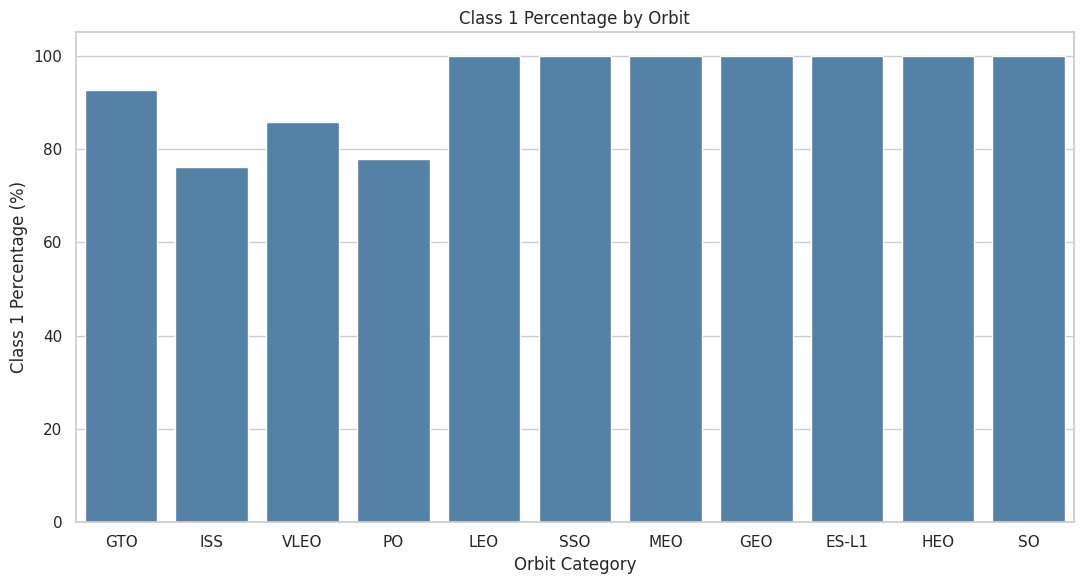

In [9]:
# Step 9: Analyze Class 1 percentage by orbit

orbit_results = (
    df.groupby("Orbit")["Class"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

orbit_results["Class1Percentage"] = (
    orbit_results["mean"] * 100
)

orbit_results = orbit_results.sort_values(
    "count",
    ascending=False
)

print("Class 1 percentage by orbit:")
display(orbit_results)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=orbit_results,
    x="Orbit",
    y="Class1Percentage",
    color="steelblue"
)

plt.title("Class 1 Percentage by Orbit")
plt.xlabel("Orbit Category")
plt.ylabel("Class 1 Percentage (%)")
plt.ylim(0, 105)
plt.tight_layout()

plt.show()

## Step 10 — Flight Number vs Orbit

Visualize the distribution of orbital mission categories across
Falcon 9 flight numbers, distinguishing Class 0 and Class 1 records.

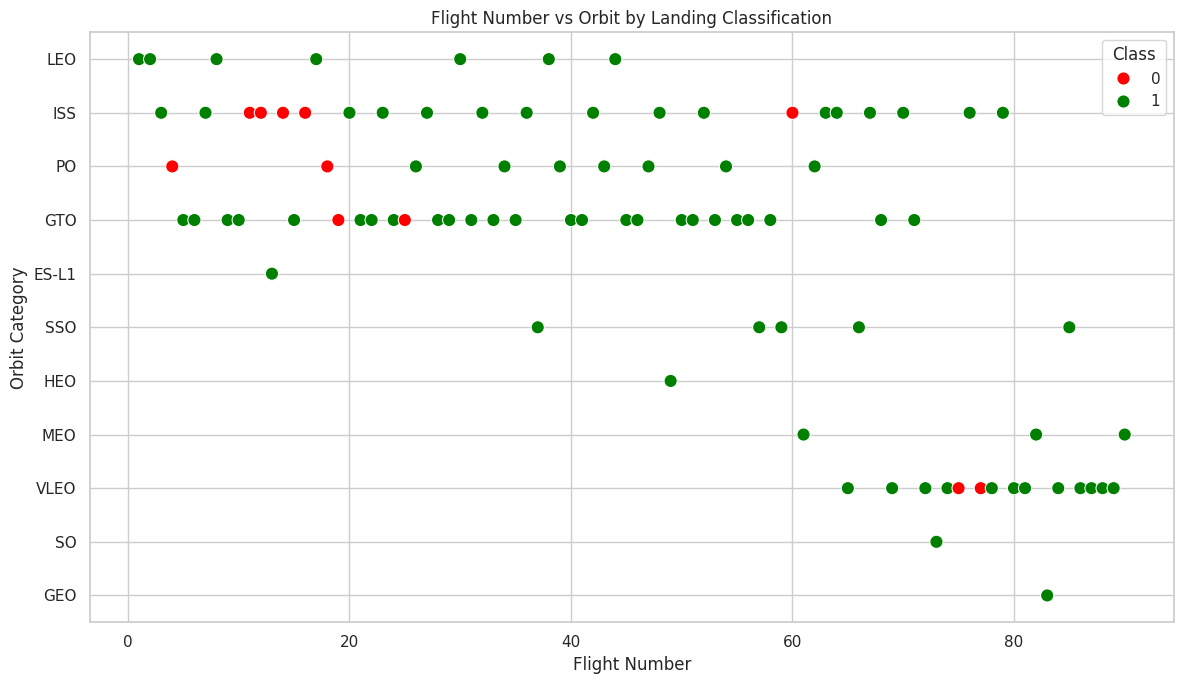

In [10]:
# Step 10: Flight Number vs Orbit

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="FlightNumber",
    y="Orbit",
    hue="Class",
    palette={0: "red", 1: "green"},
    s=90
)

plt.title("Flight Number vs Orbit by Landing Classification")
plt.xlabel("Flight Number")
plt.ylabel("Orbit Category")
plt.legend(title="Class")
plt.tight_layout()

plt.show()

## Step 11 — Booster Reusability vs Landing Classification

Compare the Class 1 percentage between previously reused
and non-reused Falcon 9 boosters using Pandas and Seaborn.

Booster reuse analysis:


,Reused,count,sum,mean,Class1Percentage,ReuseStatus
0,False,53,44,0.830189,83.018868,Not Reused
1,True,37,35,0.945946,94.594595,Reused


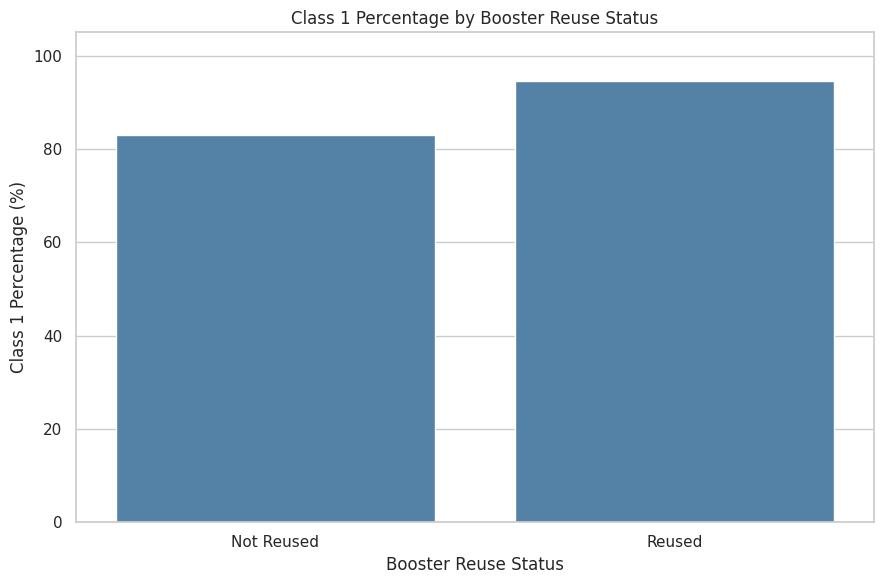

In [11]:
# Step 11: Analyze booster reusability

reuse_results = (
    df.groupby("Reused")["Class"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

reuse_results["Class1Percentage"] = (
    reuse_results["mean"] * 100
)

reuse_results["ReuseStatus"] = reuse_results["Reused"].map({
    False: "Not Reused",
    True: "Reused"
})

print("Booster reuse analysis:")
display(reuse_results)

plt.figure(figsize=(9, 6))

sns.barplot(
    data=reuse_results,
    x="ReuseStatus",
    y="Class1Percentage",
    color="steelblue"
)

plt.title("Class 1 Percentage by Booster Reuse Status")
plt.xlabel("Booster Reuse Status")
plt.ylabel("Class 1 Percentage (%)")
plt.ylim(0, 105)
plt.tight_layout()

plt.show()

## Step 12 — Booster Block vs Landing Classification

Compare the Class 1 percentage across Falcon 9 booster blocks
to investigate differences in the course-defined landing
classification.

Class 1 percentage by booster block:


,Block,count,sum,mean,Class1Percentage
0,1.0,19,12,0.631579,63.157895
1,2.0,6,6,1.000000,100.000000
2,3.0,15,14,0.933333,93.333333
3,4.0,11,11,1.000000,100.000000
4,5.0,39,36,0.923077,92.307692


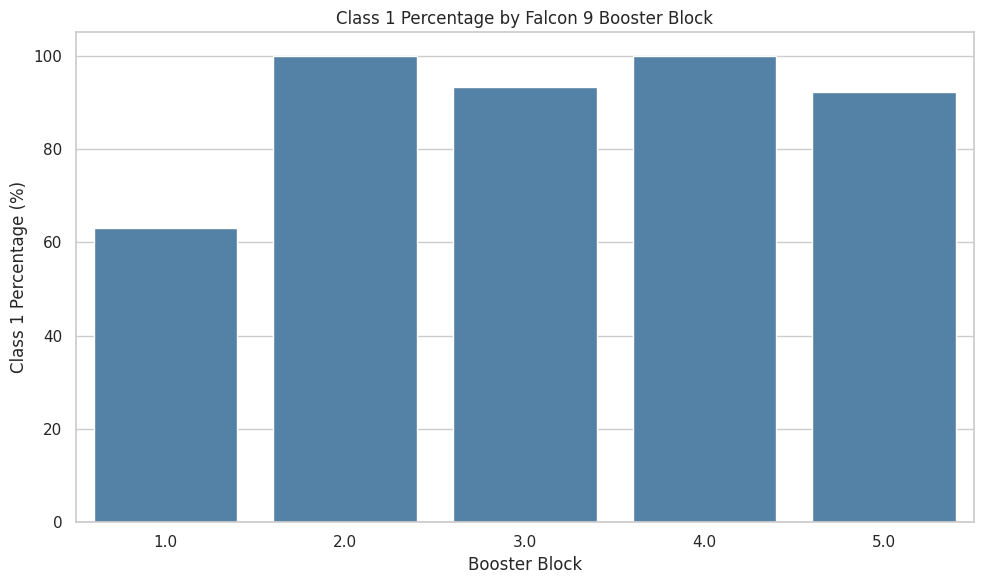

In [12]:
# Step 12: Analyze landing classification by booster block

block_results = (
    df.groupby("Block")["Class"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

block_results["Class1Percentage"] = (
    block_results["mean"] * 100
)

print("Class 1 percentage by booster block:")
display(block_results)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=block_results,
    x="Block",
    y="Class1Percentage",
    color="steelblue"
)

plt.title("Class 1 Percentage by Falcon 9 Booster Block")
plt.xlabel("Booster Block")
plt.ylabel("Class 1 Percentage (%)")
plt.ylim(0, 105)
plt.tight_layout()

plt.show()

## Step 13 — Correlation Analysis

Calculate Pearson correlation coefficients between selected
numerical launch characteristics and the course-defined
landing classification.

Visualize the correlation matrix using a Seaborn heatmap.

Correlation matrix:


,FlightNumber,PayloadMass,Flights,Block,ReusedCount,Class
FlightNumber,1.000,0.596,0.653,0.932,0.735,0.221
PayloadMass,0.596,1.000,0.665,0.518,0.612,0.093
Flights,0.653,0.665,1.000,0.520,0.685,0.047
Block,0.932,0.518,0.520,1.000,0.743,0.289
ReusedCount,0.735,0.612,0.685,0.743,1.000,0.224
Class,0.221,0.093,0.047,0.289,0.224,1.000


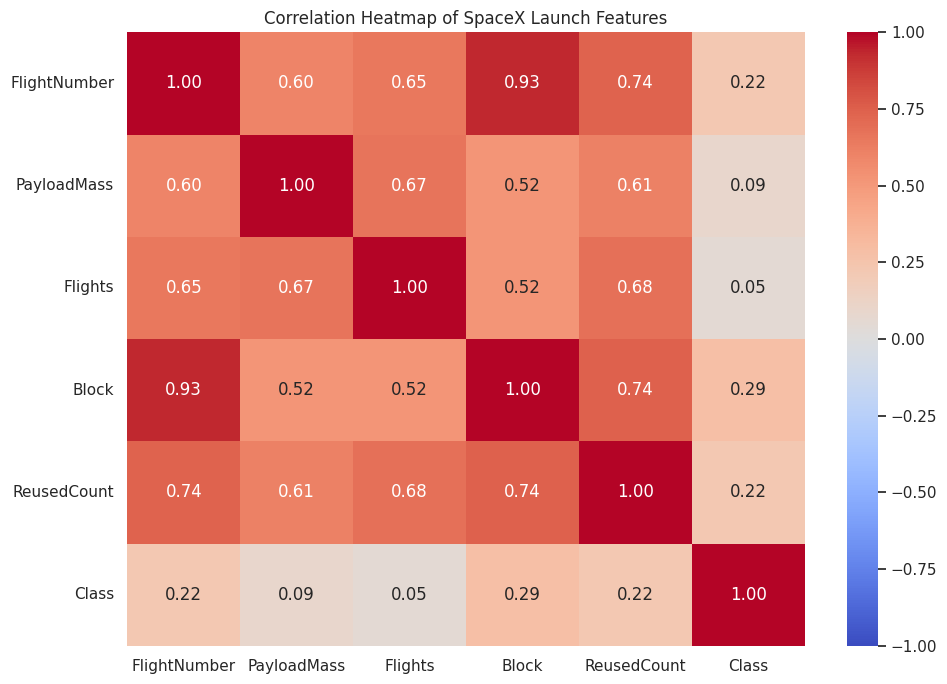

In [13]:
# Step 13: Correlation heatmap

numeric_features = [
    "FlightNumber",
    "PayloadMass",
    "Flights",
    "Block",
    "ReusedCount",
    "Class"
]

correlation_matrix = df[numeric_features].corr()

print("Correlation matrix:")
display(correlation_matrix.round(3))

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Heatmap of SpaceX Launch Features")
plt.tight_layout()

plt.show()

## Step 14 — Annual Class 1 Trends

Analyze how the Class 1 percentage changes across launch years
using Pandas and Seaborn.

Annual Class 1 trends:


,Year,count,sum,mean,Class1Percentage
0,2010,1,1,1.000000,100.000000
1,2012,1,1,1.000000,100.000000
2,2013,3,2,0.666667,66.666667
3,2014,6,5,0.833333,83.333333
4,2015,6,3,0.500000,50.000000
5,2016,8,5,0.625000,62.500000
6,2017,18,18,1.000000,100.000000
7,2018,18,17,0.944444,94.444444
8,2019,10,10,1.000000,100.000000
9,2020,19,17,0.894737,89.473684


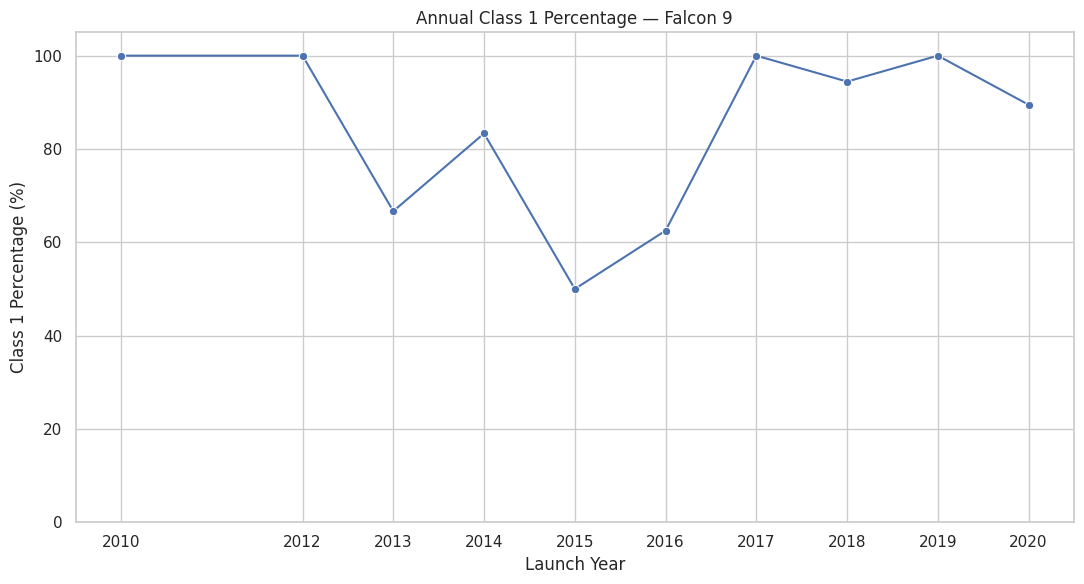

In [14]:
# Step 14: Annual Class 1 trend analysis

df["Date"] = pd.to_datetime(df["Date"])

df["Year"] = df["Date"].dt.year

yearly_trends = (
    df.groupby("Year")["Class"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

yearly_trends["Class1Percentage"] = (
    yearly_trends["mean"] * 100
)

print("Annual Class 1 trends:")
display(yearly_trends)

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=yearly_trends,
    x="Year",
    y="Class1Percentage",
    marker="o"
)

plt.title("Annual Class 1 Percentage — Falcon 9")
plt.xlabel("Launch Year")
plt.ylabel("Class 1 Percentage (%)")
plt.ylim(0, 105)
plt.xticks(yearly_trends["Year"])
plt.tight_layout()

plt.show()

## Step 15 — Final EDA Validation

Verify the dataset dimensions, target distribution, missing
values, and derived analysis columns before completing the notebook.

In [15]:
# Step 15: Final EDA validation

print("Total records:", len(df))
print("Current number of columns:", df.shape[1])

print("\nTarget distribution:")
print(df["Class"].value_counts().sort_index())

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDerived EDA columns:")
print([col for col in ["FlightGroup", "PayloadGroup", "Year"]
       if col in df.columns])

print("\nDuplicate flight numbers:",
      df["FlightNumber"].duplicated().sum())

assert len(df) == 90, "Unexpected record count"
assert df["Class"].value_counts().to_dict() == {0: 11, 1: 79}
assert df["FlightNumber"].is_unique

print("\nEDA validation passed!")

Total records: 90
Current number of columns: 21

Target distribution:
Class
0    11
1    79
Name: count, dtype: int64

Missing values:
LandingPad    26
dtype: int64

Derived EDA columns:
['FlightGroup', 'PayloadGroup', 'Year']

Duplicate flight numbers: 0

EDA validation passed!
